# Exploratory Data Analysis and Insights on Seoul Bike Sharing Demand Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to explore hourly transportation and weather data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Checking data quality
- Converting text into dates
- Exploring hourly, seasonal, and weather measurements
- Selecting, filtering, and sorting records
- Grouping and aggregating hourly observations
- Creating time-based and demand-level columns
- Examining correlations
- Creating basic time-series visualizations
- Exporting an analyzed DataFrame


## About the Dataset

The **SeoulBikeSharing.csv** dataset contains **8,760 hourly observations** from the Seoul public bike-sharing system. The records cover one year and include rental demand, weather measurements, holiday information, and service availability.

It contains **14 columns**:

| Column | Description |
|---|---|
| `date` | Observation date |
| `rented_bike_count` | Number of bikes rented during the hour |
| `hour` | Hour of the day from 0 to 23 |
| `temperature_c` | Temperature in degrees Celsius |
| `humidity_percent` | Relative humidity percentage |
| `wind_speed_m_s` | Wind speed in metres per second |
| `visibility_10m` | Visibility measured in units of 10 metres |
| `dew_point_temperature_c` | Dew-point temperature in degrees Celsius |
| `solar_radiation_mj_m2` | Solar radiation in megajoules per square metre |
| `rainfall_mm` | Rainfall in millimetres |
| `snowfall_cm` | Snowfall in centimetres |
| `season` | Winter, Spring, Summer, or Autumn |
| `holiday` | Holiday or No Holiday |
| `functioning_day` | Whether the bike-sharing system was operating |

The original descriptive column names were converted to concise snake_case names. The hourly records and measurements were not changed.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will work with dates and hours, compare demand across seasons and weather conditions, create useful time and demand indicators, and visualize rental activity.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **SeoulBikeSharing.csv** into a DataFrame named `df`.


In [1]:
import pandas as pd
df=pd.read_csv(r"E:\Liha tech\LIHA tech Assignment\Pandas_Assignment\Assignment_no_12\SeoulBikeSharing.csv")

### Question 2
Display the first **5 rows** of the dataset.


In [ ]:
df.head()

### Question 3
Display the last **5 rows** of the dataset.


In [ ]:
df.tail()

### Question 4
Find the total number of **rows and columns** in the dataset.


In [3]:
df.shape

(8760, 14)

### Question 5
Display all the **column names** in the dataset.


In [4]:
df.columns


Index(['date', 'rented_bike_count', 'hour', 'temperature_c',
       'humidity_percent', 'wind_speed_m_s', 'visibility_10m',
       'dew_point_temperature_c', 'solar_radiation_mj_m2', 'rainfall_mm',
       'snowfall_cm', 'season', 'holiday', 'functioning_day'],
      dtype='object')

### Question 6
Display the **data type of each column**.


In [5]:
df.dtypes

date                        object
rented_bike_count            int64
hour                         int64
temperature_c              float64
humidity_percent             int64
wind_speed_m_s             float64
visibility_10m               int64
dew_point_temperature_c    float64
solar_radiation_mj_m2      float64
rainfall_mm                float64
snowfall_cm                float64
season                      object
holiday                     object
functioning_day             object
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     8760 non-null   object 
 1   rented_bike_count        8760 non-null   int64  
 2   hour                     8760 non-null   int64  
 3   temperature_c            8760 non-null   float64
 4   humidity_percent         8760 non-null   int64  
 5   wind_speed_m_s           8760 non-null   float64
 6   visibility_10m           8760 non-null   int64  
 7   dew_point_temperature_c  8760 non-null   float64
 8   solar_radiation_mj_m2    8760 non-null   float64
 9   rainfall_mm              8760 non-null   float64
 10  snowfall_cm              8760 non-null   float64
 11  season                   8760 non-null   object 
 12  holiday                  8760 non-null   object 
 13  functioning_day          8760 non-null   object 
dtypes: float64(6), int64(4),

## 2. Checking Data Quality and Converting Dates

### Question 8
Display the number of **missing values in each column**.


In [7]:
df.isnull().sum()

date                       0
rented_bike_count          0
hour                       0
temperature_c              0
humidity_percent           0
wind_speed_m_s             0
visibility_10m             0
dew_point_temperature_c    0
solar_radiation_mj_m2      0
rainfall_mm                0
snowfall_cm                0
season                     0
holiday                    0
functioning_day            0
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [8]:
df.isnull().sum().sum()

np.int64(0)

### Question 10
Check the number of **duplicate rows** in the dataset.


In [9]:
df.duplicated().sum()

np.int64(0)

### Question 11
Create a new DataFrame named `df_clean` using `df.drop_duplicates().copy()`, then display its shape.


In [10]:
df_clean=df.drop_duplicates().copy()

### Question 12
Convert the `date` column in `df_clean` to Pandas datetime format using `pd.to_datetime()` with `dayfirst=True`.


In [ ]:
# pd.to_datetime(df_clean["date"],"%d/%m/%Y")
# # df_clean["date"].tail(50)

df_clean["date"]=pd.to_datetime(df["date"],dayfirst=True)
df_clean['date']#standard date format of the pandas is yyyy/mm/dd


0      2017-12-01
1      2017-12-01
2      2017-12-01
3      2017-12-01
4      2017-12-01
          ...    
8755   2018-11-30
8756   2018-11-30
8757   2018-11-30
8758   2018-11-30
8759   2018-11-30
Name: date, Length: 8760, dtype: datetime64[ns]

## 3. Selecting Rows and Columns

### Question 13
Select and display only the **rented_bike_count** column from `df_clean`.


In [22]:
df_clean["rented_bike_count"]

0        254
1        204
2        173
3        107
4         78
        ... 
8755    1003
8756     764
8757     694
8758     712
8759     584
Name: rented_bike_count, Length: 8760, dtype: int64

### Question 14
Select and display the **date, hour, temperature_c, humidity_percent, season, and rented_bike_count** columns.


In [23]:
df_clean[["date","temperature_c","humidity_percent","season","rented_bike_count"]]

,date,temperature_c,humidity_percent,season,rented_bike_count
0,2017-12-01,-5.2,37,Winter,254
1,2017-12-01,-5.5,38,Winter,204
2,2017-12-01,-6.0,39,Winter,173
3,2017-12-01,-6.2,40,Winter,107
4,2017-12-01,-6.0,36,Winter,78
...,...,...,...,...,...
8755,2018-11-30,4.2,34,Autumn,1003
8756,2018-11-30,3.4,37,Autumn,764
8757,2018-11-30,2.6,39,Autumn,694
8758,2018-11-30,2.1,41,Autumn,712


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns**.


In [24]:
df.iloc[0:5,0:6]

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s
0,01/12/2017,254,0,-5.2,37,2.2
1,01/12/2017,204,1,-5.5,38,0.8
2,01/12/2017,173,2,-6.0,39,1.0
3,01/12/2017,107,3,-6.2,40,0.9
4,01/12/2017,78,4,-6.0,36,2.3


### Question 16
Using `loc`, display rows **10 to 15** for the columns **date, hour, rainfall_mm, snowfall_cm, and rented_bike_count**.


In [25]:
df_clean.loc[10:15,["date","hour","rainfall_mm","snowfall_cm","rented_bike_count"]]

,date,hour,rainfall_mm,snowfall_cm,rented_bike_count
10,2017-12-01,10,0.0,0.0,339
11,2017-12-01,11,0.0,0.0,360
12,2017-12-01,12,0.0,0.0,449
13,2017-12-01,13,0.0,0.0,451
14,2017-12-01,14,0.0,0.0,447
15,2017-12-01,15,0.0,0.0,463


## 4. Categories and Descriptive Statistics

### Question 17
Count the number of hourly records for each **season** using `value_counts()`.


In [26]:
df_clean["season"].value_counts()

season
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

### Question 18
Count the values in the **holiday** and **functioning_day** columns.


In [28]:
df_clean["functioning_day"].value_counts()
df_clean["holiday"].value_counts()

holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

### Question 19
Display descriptive statistics for the numeric columns using `describe()`.


In [29]:
df_clean.describe()

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,2018-05-31 23:59:59.999999744,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
min,2017-12-01 00:00:00,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,2018-03-02 00:00:00,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,2018-06-01 00:00:00,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,2018-08-31 00:00:00,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,2018-11-30 00:00:00,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000
std,NaN,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746


### Question 20
Calculate the **mean rented_bike_count** for all hourly records.


In [30]:
df_clean["rented_bike_count"].mean()

np.float64(704.6020547945205)

### Question 21
Find the record with the **highest rented_bike_count**.


In [31]:
df_clean["rented_bike_count"].max()

3556

### Question 22
Calculate the mean **temperature_c** and mean **humidity_percent**.


In [32]:
df[["temperature_c","humidity_percent"]].mean()

temperature_c       12.882922
humidity_percent    58.226256
dtype: float64

## 5. Filtering and Sorting

### Question 23
Display all hourly records where **rented_bike_count is greater than 1,000**.


In [33]:
df_clean[df_clean["rented_bike_count"]>1000]

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm,season,holiday,functioning_day
2222,2018-03-03,1025,14,14.4,14,1.4,1833,-12.8,2.66,0.0,0.0,Spring,No Holiday,Yes
2223,2018-03-03,1238,15,16.0,14,2.2,1828,-11.5,2.33,0.0,0.0,Spring,No Holiday,Yes
2224,2018-03-03,1285,16,15.8,15,2.6,1867,-10.8,1.70,0.0,0.0,Spring,No Holiday,Yes
2225,2018-03-03,1197,17,15.0,22,2.5,1946,-6.5,0.96,0.0,0.0,Spring,No Holiday,Yes
2274,2018-03-05,1155,18,8.1,47,1.7,2000,-2.5,0.34,0.0,0.0,Spring,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8731,2018-11-29,1026,19,5.2,48,1.9,1590,-4.9,0.00,0.0,0.0,Autumn,No Holiday,Yes
8744,2018-11-30,1527,8,-1.5,68,1.1,1286,-6.6,0.02,0.0,0.0,Autumn,No Holiday,Yes
8753,2018-11-30,1047,17,6.0,29,2.1,1877,-10.7,0.23,0.0,0.0,Autumn,No Holiday,Yes
8754,2018-11-30,1384,18,4.7,34,1.9,1661,-9.8,0.00,0.0,0.0,Autumn,No Holiday,Yes


### Question 24
Display all records where **rainfall_mm is greater than zero**.


In [34]:
df_clean[df_clean["rainfall_mm"]>0]

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm,season,holiday,functioning_day
51,2017-12-03,117,3,3.4,71,1.6,1011,-1.3,0.00,0.5,0.0,Winter,No Holiday,Yes
54,2017-12-03,13,6,3.4,86,2.5,278,1.2,0.00,1.0,0.0,Winter,No Holiday,Yes
57,2017-12-03,152,9,3.5,91,1.8,231,2.1,0.02,2.5,0.0,Winter,No Holiday,Yes
78,2017-12-04,200,6,1.2,76,3.7,371,-2.5,0.00,0.1,0.0,Winter,No Holiday,Yes
120,2017-12-06,145,0,-2.8,77,0.0,331,-6.2,0.00,0.1,0.1,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8241,2018-11-09,0,9,10.8,78,2.6,1985,7.1,0.13,0.5,0.0,Autumn,No Holiday,No
8520,2018-11-21,119,0,7.2,74,1.2,772,2.8,0.00,0.2,0.0,Autumn,No Holiday,Yes
8523,2018-11-21,112,3,6.5,87,1.0,710,4.4,0.00,1.0,0.0,Autumn,No Holiday,Yes
8601,2018-11-24,24,9,0.3,97,3.0,34,-0.1,0.00,9.1,7.1,Autumn,No Holiday,Yes


### Question 25
Display all records where **snowfall_cm is greater than zero**.


In [35]:
df_clean[df_clean["snowfall_cm"]>0]

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm,season,holiday,functioning_day
120,2017-12-06,145,0,-2.8,77,0.0,331,-6.2,0.00,0.1,0.1,Winter,No Holiday,Yes
121,2017-12-06,144,1,-3.0,79,0.0,293,-6.1,0.00,0.0,0.3,Winter,No Holiday,Yes
122,2017-12-06,117,2,-3.0,79,0.0,1862,-6.1,0.00,0.0,0.4,Winter,No Holiday,Yes
123,2017-12-06,78,3,-3.2,78,0.0,1808,-6.4,0.00,0.2,0.4,Winter,No Holiday,Yes
124,2017-12-06,58,4,-3.4,75,0.0,1982,-7.2,0.00,0.0,0.4,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8645,2018-11-26,115,5,2.1,88,1.4,323,0.3,0.00,0.0,0.3,Autumn,No Holiday,Yes
8646,2018-11-26,339,6,1.8,88,1.1,313,0.0,0.00,0.0,0.3,Autumn,No Holiday,Yes
8647,2018-11-26,819,7,1.7,89,1.3,295,0.0,0.00,0.0,0.3,Autumn,No Holiday,Yes
8648,2018-11-26,1524,8,2.0,84,1.1,396,-0.4,0.03,0.0,0.3,Autumn,No Holiday,Yes


### Question 26
Using `query()`, display records where **temperature_c is greater than 25** and **humidity_percent is below 60**.


In [36]:
df_clean.query("temperature_c>25 and humidity_percent<60")

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm,season,holiday,functioning_day
3374,2018-04-20,970,14,25.9,28,2.2,808,5.9,2.92,0.0,0.0,Spring,No Holiday,Yes
3375,2018-04-20,1080,15,26.1,27,1.8,581,5.6,2.59,0.0,0.0,Spring,No Holiday,Yes
3376,2018-04-20,1206,16,25.7,30,3.4,600,6.8,2.07,0.0,0.0,Spring,No Holiday,Yes
3377,2018-04-20,1543,17,25.6,30,2.3,671,6.7,1.47,0.0,0.0,Spring,No Holiday,Yes
3785,2018-05-07,2392,17,25.5,31,2.3,1974,7.1,1.50,0.0,0.0,Spring,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7263,2018-09-29,2065,15,26.5,33,1.4,2000,8.9,2.25,0.0,0.0,Autumn,No Holiday,Yes
7264,2018-09-29,2254,16,26.6,34,1.3,2000,9.4,1.69,0.0,0.0,Autumn,No Holiday,Yes
7265,2018-09-29,2432,17,26.3,31,1.0,2000,7.8,1.03,0.0,0.0,Autumn,No Holiday,Yes
7383,2018-10-04,0,15,25.3,39,1.6,2000,10.3,1.88,0.0,0.0,Autumn,No Holiday,No


### Question 27
Display all records where **functioning_day is equal to `No`**.


In [37]:
df_clean[df_clean["functioning_day"]=="No"]

,date,rented_bike_count,hour,temperature_c,humidity_percent,wind_speed_m_s,visibility_10m,dew_point_temperature_c,solar_radiation_mj_m2,rainfall_mm,snowfall_cm,season,holiday,functioning_day
3144,2018-04-11,0,0,14.4,82,4.6,1041,11.3,0.0,0.0,0.0,Spring,No Holiday,No
3145,2018-04-11,0,1,13.6,81,3.6,886,10.3,0.0,0.0,0.0,Spring,No Holiday,No
3146,2018-04-11,0,2,12.7,80,3.9,885,9.3,0.0,0.0,0.0,Spring,No Holiday,No
3147,2018-04-11,0,3,11.6,81,3.1,687,8.4,0.0,0.0,0.0,Spring,No Holiday,No
3148,2018-04-11,0,4,10.2,83,3.5,554,7.4,0.0,0.0,0.0,Spring,No Holiday,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8251,2018-11-09,0,19,11.9,71,2.7,589,6.7,0.0,0.0,0.0,Autumn,No Holiday,No
8252,2018-11-09,0,20,11.9,72,2.5,526,7.0,0.0,0.0,0.0,Autumn,No Holiday,No
8253,2018-11-09,0,21,11.4,74,1.9,498,6.9,0.0,0.0,0.0,Autumn,No Holiday,No
8254,2018-11-09,0,22,11.2,75,1.7,478,6.9,0.0,0.0,0.0,Autumn,No Holiday,No


### Question 28
Sort `df_clean` by **rented_bike_count in descending order** and display the first 10 rows.


In [41]:
df_clean.sort_values(by="rented_bike_count",ascending=False).head(10)
df_clean.columns


Index(['date', 'rented_bike_count', 'hour', 'temperature_c',
       'humidity_percent', 'wind_speed_m_s', 'visibility_10m',
       'dew_point_temperature_c', 'solar_radiation_mj_m2', 'rainfall_mm',
       'snowfall_cm', 'season', 'holiday', 'functioning_day'],
      dtype='object')

## 6. Grouping and Aggregation

### Question 29
Calculate the **average rented_bike_count for each hour of the day**.


In [42]:
df_clean.groupby("hour")["rented_bike_count"].mean()

hour
0      541.460274
1      426.183562
2      301.630137
3      203.331507
4      132.591781
5      139.082192
6      287.564384
7      606.005479
8     1015.701370
9      645.983562
10     527.821918
11     600.852055
12     699.441096
13     733.246575
14     758.824658
15     829.186301
16     930.621918
17    1138.509589
18    1502.926027
19    1195.147945
20    1068.964384
21    1031.449315
22     922.797260
23     671.126027
Name: rented_bike_count, dtype: float64

### Question 30
Calculate the **average rented_bike_count for each season**.


In [43]:
df_clean.groupby("season")["rented_bike_count"].mean()

season
Autumn     819.597985
Spring     730.031250
Summer    1034.073370
Winter     225.541204
Name: rented_bike_count, dtype: float64

### Question 31
Calculate the **average rented_bike_count for holiday and non-holiday records**.


In [44]:
df_clean.groupby("holiday")["rented_bike_count"].mean()

holiday
Holiday       499.756944
No Holiday    715.228026
Name: rented_bike_count, dtype: float64

### Question 32
Calculate total bike rentals for each **month number** using the `date` column.


In [47]:
df_clean.groupby(df_clean["date"].dt.month_name())["rented_bike_count"].mean()

date
April         728.093056
August        876.192204
December      249.099462
February      225.941964
January       201.620968
July          987.177419
June         1245.676389
March         511.551075
May           950.387097
November      646.826389
October       874.563172
September     935.572222
Name: rented_bike_count, dtype: float64

### Question 33
Determine which hour of the day has the **highest average rented_bike_count**.


In [48]:
df_clean.groupby("hour")["rented_bike_count"].mean().idxmax()

np.int64(18)

## 7. Creating and Modifying Columns

### Question 34
Create a new column named **month_name** from `date` using the `.dt.month_name()` method.


In [49]:
df_clean["month_name"]=df_clean["date"].dt.month_name()

### Question 35
Create a column named **day_type** using the day of week from `date`. Store `Weekend` for Saturday and Sunday; otherwise store `Weekday`.


In [57]:
df_clean["day_type"]=df_clean["date"].dt.weekday.apply(lambda x:"Weekend" if x==5|x==6 else "Weekday")


### Question 36
Create a column named **demand_level** using `apply()` with a `lambda` function. Store `High` when `rented_bike_count` is greater than or equal to 1,000; otherwise store `Normal`.


In [58]:
df_clean["demand_level"]=df_clean["rented_bike_count"].apply(lambda x:"High" if x>=1000 else "Normal")

## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **rented_bike_count, temperature_c, humidity_percent, wind_speed_m_s, rainfall_mm, and snowfall_cm**.


In [60]:
df_clean[["rented_bike_count","temperature_c","humidity_percent","wind_speed_m_s","rainfall_mm","snowfall_cm"]].corr()

,rented_bike_count,temperature_c,humidity_percent,wind_speed_m_s,rainfall_mm,snowfall_cm
rented_bike_count,1.000000,0.538558,-0.199780,0.121108,-0.123074,-0.141804
temperature_c,0.538558,1.000000,0.159371,-0.036252,0.050282,-0.218405
humidity_percent,-0.199780,0.159371,1.000000,-0.336683,0.236397,0.108183
wind_speed_m_s,0.121108,-0.036252,-0.336683,1.000000,-0.019674,-0.003554
rainfall_mm,-0.123074,0.050282,0.236397,-0.019674,1.000000,0.008500
snowfall_cm,-0.141804,-0.218405,0.108183,-0.003554,0.008500,1.000000


### Question 38
Create a **line chart** showing total daily bike rentals over `date`.


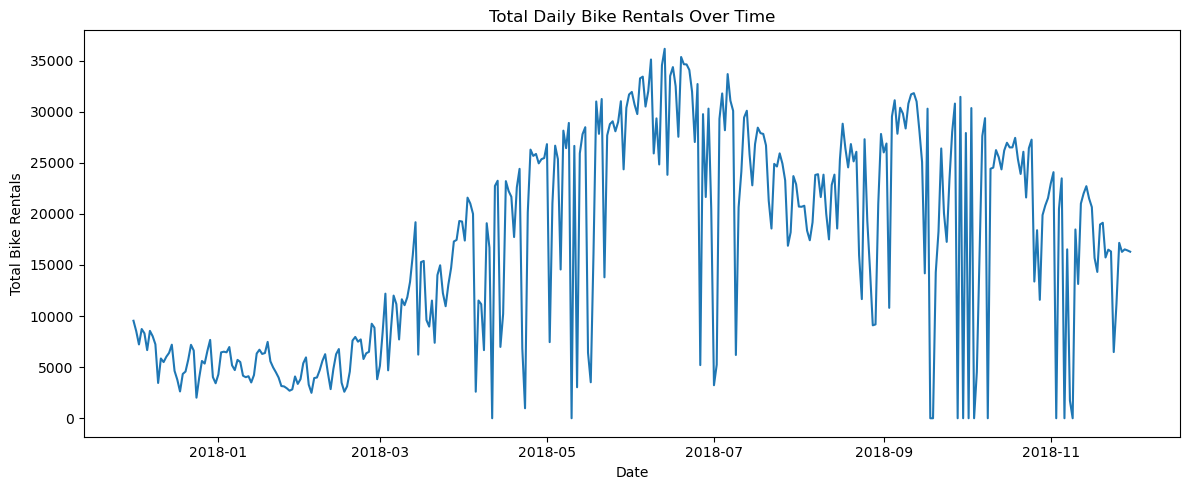

In [65]:

import matplotlib.pyplot as plt

x = df_clean.groupby("date")["rented_bike_count"].sum()
plt.figure(figsize=(12, 5))
plt.plot(x.index, x.values)
plt.title("Total Daily Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")
plt.tight_layout()
plt.show()


### Question 39
Create a **bar chart** showing the average rented bike count for each hour of the day.


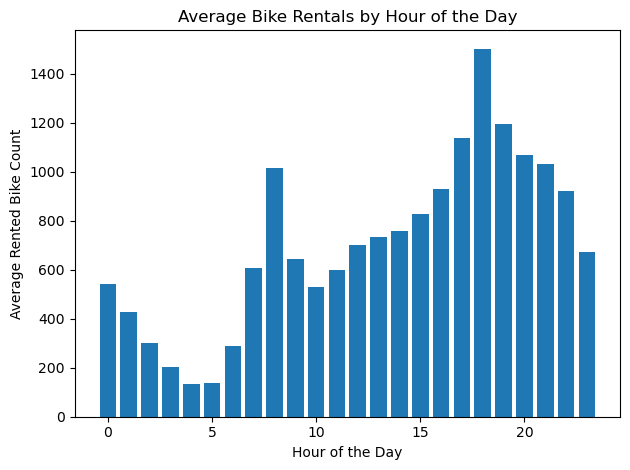

In [69]:

import matplotlib.pyplot as plt

hour = df_clean.groupby("hour")["rented_bike_count"].mean()


plt.bar(hour.index, hour.values)

plt.title("Average Bike Rentals by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rented Bike Count")
plt.tight_layout()
plt.show()


### Question 40
Save `df_clean` as **SeoulBikeSharing_Analyzed.csv** using `to_csv()` without saving the index.


In [70]:
df_clean.to_csv("SeoulBikeSharing_Analyzed.csv",index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with hourly transportation data, datetime features, grouped demand summaries, and basic time-series visualizations before moving to forecasting or predictive modeling.
